# EUR/USD anomaly detection with path signatures: new FX channels

A cleaned, FX-only version of `anomaly/anomaly_experiments.ipynb`. Same question: does a
signature-based anomaly score tell us something about the coming period **beyond** what a volatility
model already knows? An anomaly is judged against *surprise*: realized volatility far above the HAR
forecast (the top 20% of log(realized / forecast)), and scored within strata of the HAR forecast so a
detector gets no credit for just finding high-volatility periods.

What changed from the original notebook:

- **Channels are the one thing that varies** (5 sets), including the new FX channels: time-of-day-adjusted
  price and range, and the abnormal bid-ask spread (see `vol_fx.ipynb`, section 1).
- **Everything else is fixed in advance**: windows normalized by the volatility before them (so detectors
  see shape, not level), one window length (one trading week for 1 day, one trading month for 5 days),
  lead-lag paths, signature depths 2 and 3. The original grid had about 250 configs, which overfit the
  selection.
- **Detectors**: Mahalanobis and Isolation Forest on every config, then the HMM on the top 3 signature
  configs and the best config of each control. The autoencoder is dropped to save time (it is the slowest detector).
- No crypto branch, no add-the-HMM-afterwards cell.

Run this before section 7 of `vol_fx.ipynb`, which uses the detectors selected here.

In [4]:
import logging

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import fx_lab as L
from anomaly import report as R, run as RUN

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(message)s", datefmt="%H:%M:%S", force=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

QUICK = False  # True: data from 2021 and fewer bootstrap draws, to check that everything runs

## 1. Configuration

| Channel set | Channels |
|---|---|
| `price` | log price (the original reference) |
| `price+volume+range+flow` | the original full set (FX "flow" is the tick rule, so weak) |
| `price_sa` | time-of-day-adjusted log price |
| `price_sa+spread` | plus the abnormal spread |
| `price_sa+volume+range_sa+spread` | everything new |

Each channel set also gives the signature-free controls built from the same window: a lag bank with as
many columns as the signature, summary stats, and raw block sums. Two volatility baselines (the current
level and the HAR forecast) are scored too.

In [5]:
cfg = L.anomaly_config(quick=QUICK)
print(len(cfg.rep_configs()), "path recipes per horizon; data", cfg.start, "to", cfg.end)
cfg

5 path recipes per horizon; data 2012-01-01 to 2026-10-31


AnomalyConfig(horizons=('1d', '5d'), asset='fx', n_folds=3, min_train_rows=200, start='2012-01-01', end='2026-10-31', symbol='EURUSD', fx_channels=True, target_rows={'1d': None, '5d': None}, channel_sets=('price', 'price+volume+range+flow', 'price_sa', 'price_sa+spread', 'price_sa+volume+range_sa+spread'), normalizations=('trailing_vol',), window_mults=(1.0,), lead_lag=(True,), depths=(2, 3), max_sig_features=3000, stage_a_detectors=('mahalanobis', 'iforest'), stage_b_top_k=3, stage_b_detectors=('hmm',), hmm_states=3, hmm_components=5, ae_epochs=60, ae_patience=8, surprise_quantile=0.8, flag_rate=0.05, n_bootstrap=500, seed=0, data_dir='/Users/mihikaghaisas/Desktop/CMU/MLCapstone/Mihika/data', output_dir='/Users/mihikaghaisas/Desktop/CMU/MLCapstone/vol_experiments_fx/results/anomaly', resume=True)

## 2. Run

Each horizon runs in its own process. Finished path recipes are saved under `parts/`, so an interrupted
run resumes where it stopped; finished horizons (`meta.json`) are skipped. Delete
`results/anomaly/<horizon>/` to redo one.

In [6]:
root = RUN.run_all(cfg, subprocess_per_horizon=True)
res = R.load_results(root)
pd.DataFrame(res.meta).T

00:36:19 | Dukascopy EURUSD 2017-02 (hourly)
00:36:35 | Dukascopy EURUSD 2018-02 (hourly)
00:36:36 | Dukascopy EURUSD 2018-03 (hourly)
00:36:37 | Dukascopy EURUSD 2018-04 (hourly)
00:36:38 | Dukascopy EURUSD 2018-05 (hourly)
00:36:39 | Dukascopy EURUSD 2018-06 (hourly)
00:36:40 | Dukascopy EURUSD 2018-07 (hourly)
00:36:41 | Dukascopy EURUSD 2018-08 (hourly)
00:36:42 | Dukascopy EURUSD 2018-09 (hourly)
00:36:43 | Dukascopy EURUSD 2018-10 (hourly)
00:36:44 | Dukascopy EURUSD 2018-11 (hourly)
00:36:45 | Dukascopy EURUSD 2018-12 (hourly)
00:36:46 | Dukascopy EURUSD 2019-01 (hourly)
00:36:47 | Dukascopy EURUSD 2019-02 (hourly)
00:36:48 | Dukascopy EURUSD 2019-03 (hourly)
00:36:49 | Dukascopy EURUSD 2019-04 (hourly)
00:36:50 | Dukascopy EURUSD 2019-05 (hourly)
00:36:51 | Dukascopy EURUSD 2019-06 (hourly)
00:36:52 | Dukascopy EURUSD 2019-07 (hourly)
00:36:53 | Dukascopy EURUSD 2019-08 (hourly)
00:36:54 | Dukascopy EURUSD 2019-09 (hourly)
00:36:55 | Dukascopy EURUSD 2019-10 (hourly)
00:36:56 |

,horizon,rows,folds,first_time,last_time,asset,seconds
1d,1d,3831,"[[956, 958], [1914, 958], [2872, 958]]",2012-01-31 22:00:00+00:00,2026-10-29 13:00:00+00:00,fx,199.9
5d,5d,3805,"[[946, 951], [1897, 951], [2848, 952]]",2012-03-01 22:00:00+00:00,2026-10-23 13:00:00+00:00,fx,48.4


## 3. The gate: does the best signature config beat everything signature-free?

The best signature config and the best signature-free config are chosen on folds 1-2 (`select`) and
checked on the last fold (`confirm`). The gate passes if the signature config is ahead on both, with a
block-bootstrap one-sided p < 0.05 on the last fold. 0.5 = no information beyond the HAR forecast.

In [7]:
display(R.gate_table(res).style.format(precision=3))

,Horizon,Best signature,Sig select,Sig confirm,Best signature-free,Free select,Free confirm,Last-fold diff,CI low,CI high,p (sig no better),Gate passed
0,1d,signature d3 | price_sa+volume+range_sa+spread|trailing_vol|w1|leadlag [hmm],0.541,0.488,raw | price_sa+spread|trailing_vol|w1 [mahalanobis],0.546,0.490,-0.002,-0.054,0.047,0.500,False
1,5d,signature d2 | price_sa+spread|trailing_vol|w1|leadlag [iforest],0.543,0.527,stats | trailing_vol|w1 [hmm],0.520,0.479,0.048,-0.054,0.159,0.182,False


## 4. Which channels help?

The best signature config of each channel set, per detector. Compare `price` with `price_sa` (the effect
of the time-of-day adjustment) and `price_sa` with `price_sa+spread` (the spread). `Select` is on the
selection folds, `Confirm` on the last fold; differences of a few hundredths are within noise.

In [8]:
display(L.channel_table(res).style.format(precision=3))
display(R.leaderboard(res, top=10).style.format(precision=3))

,Horizon,Channels,Detector,Best config,Select,Confirm
0,1d,price_sa+spread,hmm,signature d3 | price_sa+spread|trailing_vol|w1|leadlag,0.512,0.493
1,1d,price_sa+volume+range_sa+spread,hmm,signature d3 | price_sa+volume+range_sa+spread|trailing_vol|w1|leadlag,0.541,0.488
2,1d,price,iforest,signature d3 | price|trailing_vol|w1|leadlag,0.510,0.467
3,1d,price+volume+range+flow,iforest,signature d2 | price+volume+range+flow|trailing_vol|w1|leadlag,0.520,0.472
4,1d,price_sa,iforest,signature d3 | price_sa|trailing_vol|w1|leadlag,0.512,0.474
5,1d,price_sa+spread,iforest,signature d2 | price_sa+spread|trailing_vol|w1|leadlag,0.525,0.502
6,1d,price_sa+volume+range_sa+spread,iforest,signature d3 | price_sa+volume+range_sa+spread|trailing_vol|w1|leadlag,0.537,0.489
7,1d,price,mahalanobis,signature d2 | price|trailing_vol|w1|leadlag,0.514,0.464
8,1d,price+volume+range+flow,mahalanobis,signature d3 | price+volume+range+flow|trailing_vol|w1|leadlag,0.519,0.474
9,1d,price_sa,mahalanobis,signature d3 | price_sa|trailing_vol|w1|leadlag,0.519,0.474


,Horizon,Config,Kind,Detector,Select (folds 1-2),Confirm (last fold),AUC_surprise,Lift,AUC_level,Fwd_vol_ratio,n_features
0,1d,raw | price_sa+spread|trailing_vol|w1,raw,mahalanobis,0.546,0.490,0.516,1.128,0.574,1.175,64
1,1d,raw | price_sa+spread|trailing_vol|w1,raw,iforest,0.541,0.505,0.527,1.215,0.670,1.745,64
2,1d,signature d3 | price_sa+volume+range_sa+spread|trailing_vol|w1|leadlag,signature,hmm,0.541,0.488,0.523,1.377,0.630,1.348,819
3,1d,signature d3 | price_sa+volume+range_sa+spread|trailing_vol|w1|leadlag,signature,mahalanobis,0.538,0.507,0.523,1.238,0.646,1.319,819
4,1d,signature d3 | price_sa+volume+range_sa+spread|trailing_vol|w1|leadlag,signature,iforest,0.537,0.489,0.523,1.480,0.651,1.572,819
5,1d,raw | price_sa|trailing_vol|w1,raw,iforest,0.536,0.475,0.512,1.357,0.543,1.248,32
6,1d,raw | price_sa+volume+range_sa+spread|trailing_vol|w1,raw,iforest,0.536,0.486,0.518,1.390,0.636,1.508,128
7,1d,signature d2 | price_sa+volume+range_sa+spread|trailing_vol|w1|leadlag,signature,iforest,0.535,0.498,0.524,1.498,0.646,1.515,90
8,1d,lag bank | price_sa+spread|trailing_vol|w1|leadlag,lag bank,mahalanobis,0.534,0.488,0.507,1.266,0.542,1.189,155
9,1d,signature d2 | price_sa+volume+range_sa+spread|trailing_vol|w1|leadlag,signature,hmm,0.534,0.480,0.517,1.241,0.629,1.307,90


## 5. Synthetic check: shape-only anomalies

Test windows whose returns are re-ordered into a V or an inverted V: volatility, net move, skew and
kurtosis unchanged, only the shape differs. Shows what each selected detector *can* see in principle;
it is not evidence about real markets.

In [9]:
display(R.synthetic_table(res).style.format(precision=3))

,Horizon,Which,Config,Detector,AUC_injected
0,1d,best signature,signature d3 | price_sa+volume+range_sa+spread|trailing_vol|w1|leadlag,hmm,0.860
1,1d,best signature-free,raw | price_sa+spread|trailing_vol|w1,mahalanobis,0.914
2,5d,best signature,signature d2 | price_sa+spread|trailing_vol|w1|leadlag,iforest,0.950
3,5d,best signature-free,stats | trailing_vol|w1,hmm,0.533


## 6. Scores over time

Score percentiles of the selected detectors, with labeled FX events shaded (a case study only).

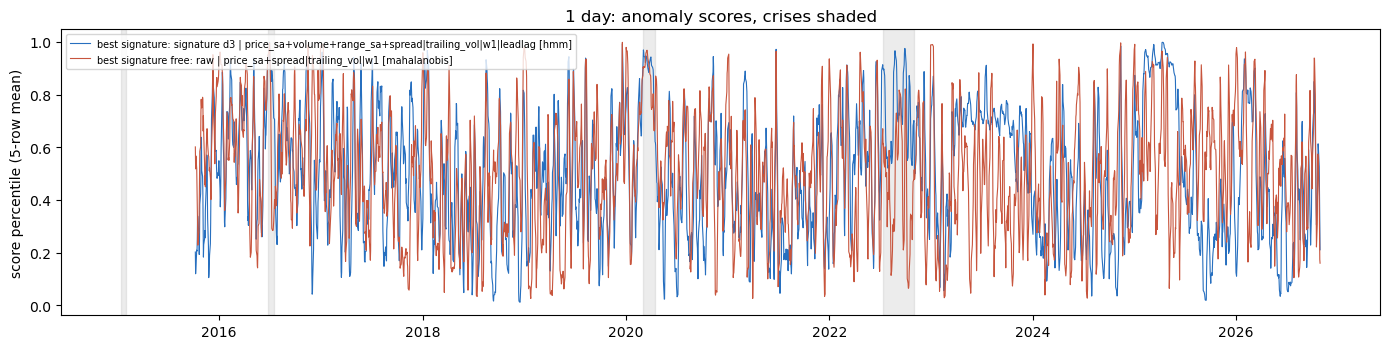

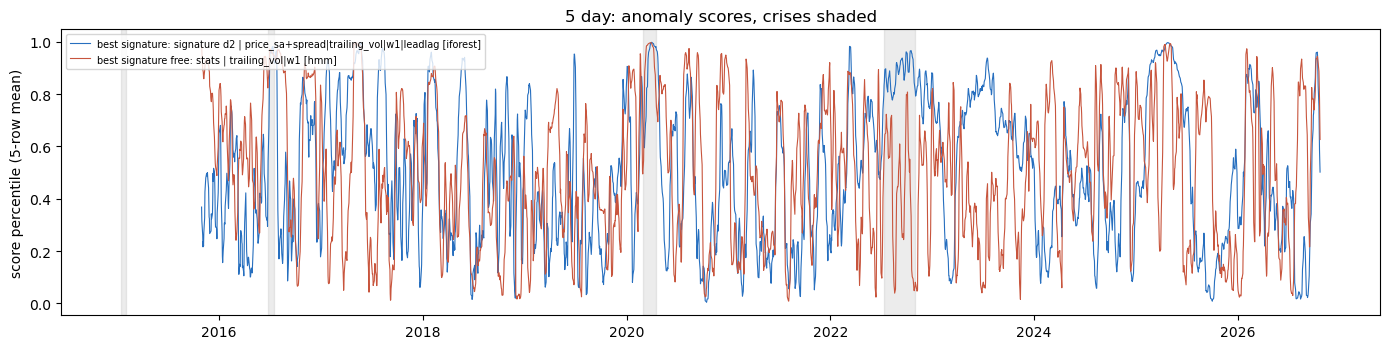

In [10]:
for hk in res.meta:
    R.plot_timeline(res, hk); plt.show()

## 7. Compared with the previous FX anomaly run

The previous run (`anomaly/results/fx/anomaly`: the original channels, the full grid) next to this one.
Different grids and end dates, so this compares the conclusions, not the numbers row by row.

In [11]:
prev_root = L.ROOT / "anomaly" / "results" / "fx" / "anomaly"
try:
    prev = R.load_results(prev_root)
    both = pd.concat({"previous": R.gate_table(prev), "new": R.gate_table(res)}, names=["Run"]).reset_index(0)
    display(both.style.format(precision=3))
except FileNotFoundError:
    print("No previous FX anomaly run found at", prev_root)

,Run,Horizon,Best signature,Sig select,Sig confirm,Best signature-free,Free select,Free confirm,Last-fold diff,CI low,CI high,p (sig no better),Gate passed
0,previous,1d,signature d3 | price+volume|trailing_vol|w2|time [mahalanobis],0.534,0.504,raw | price|trailing_vol|w2 [mahalanobis],0.544,0.529,-0.025,-0.072,0.018,0.866,False
1,previous,5d,signature d2 | price+volume|trailing_vol|w0.5|time [autoencoder],0.584,0.530,raw | price|trailing_vol|w0.5 [iforest],0.598,0.533,-0.003,-0.075,0.082,0.500,False
0,new,1d,signature d3 | price_sa+volume+range_sa+spread|trailing_vol|w1|leadlag [hmm],0.541,0.488,raw | price_sa+spread|trailing_vol|w1 [mahalanobis],0.546,0.490,-0.002,-0.054,0.047,0.500,False
1,new,5d,signature d2 | price_sa+spread|trailing_vol|w1|leadlag [iforest],0.543,0.527,stats | trailing_vol|w1 [hmm],0.520,0.479,0.048,-0.054,0.159,0.182,False


## 8. Next

`best_configs.json` in this run's folder now holds the selected detectors. Run section 7 of
`vol_fx.ipynb` to use them in the volatility forecasts.